
SMART AGRICULTURE - GWO
--------------------------------
Crop	Demand	Allocated	Shortage
Wheat          22.82       18.22       4.60
Maize          37.34       26.97      10.37
Cotton         37.87       26.35      11.52
Vegetables     29.23       23.45       5.78
--------------------------------
Total Water Demand: 127.26
Available Water: 95.0
Water Allocated: 95.0
Best Fitness: 0.285635


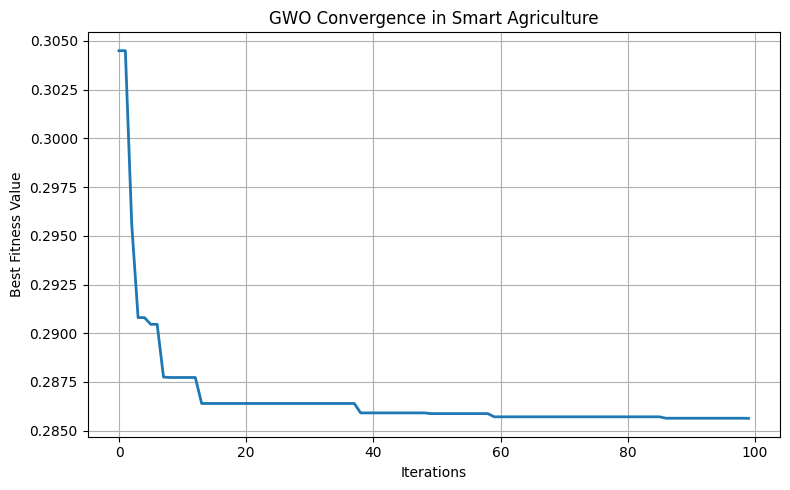

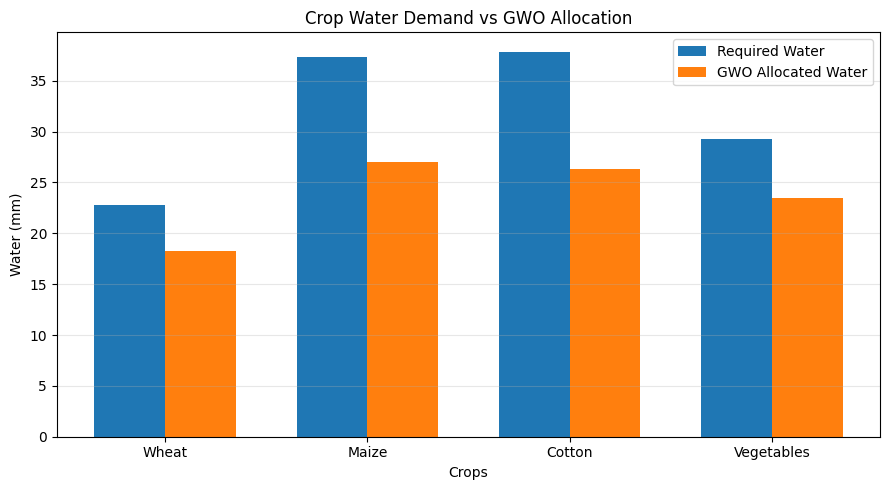

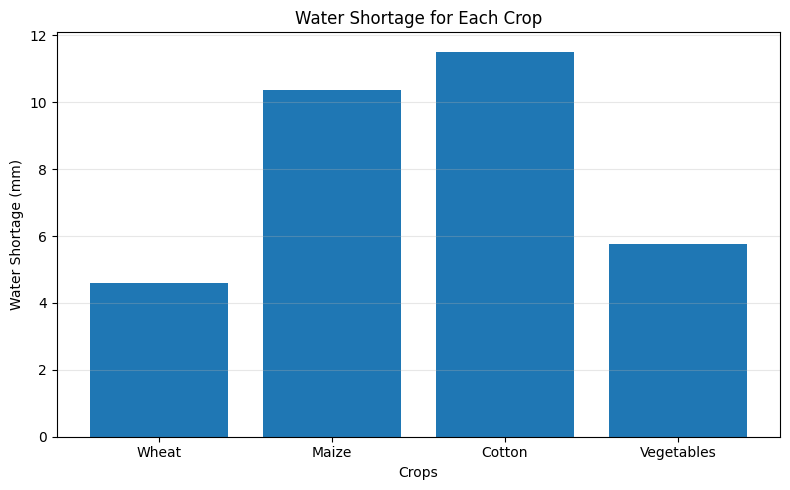

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# 1. SMART AGRICULTURE PARAMETERS
# --------------------------------

np.random.seed(42)

crops = ["Wheat", "Maize", "Cotton", "Vegetables"]

# Reference evapotranspiration (mm/day)
ET0 = np.array([4.2, 5.0, 5.4, 4.8])

# Crop coefficients
Kc = np.array([0.90, 1.15, 1.05, 1.00])

# Rainfall (mm/day)
rainfall = np.array([1.0, 0.8, 0.5, 1.2])

# Irrigation period
days = 7

# Effective rainfall coefficient
rainfall_factor = 0.52

# Crop water demand (mm for 7 days)
demand = np.maximum(
    (ET0 * Kc - rainfall_factor * rainfall) * days,
    0
)

# Priority weights
weights = np.array([1.0, 1.2, 1.1, 1.3])

# Total available water
WATER_SUPPLY = 95.0

# GWO parameters
WOLVES = 30
ITERATIONS = 100
DIM = len(crops)


# --------------------------------
# 2. REPAIR WATER ALLOCATION
# --------------------------------

def repair(position):

    # Keep allocation within crop demand
    allocation = np.clip(position, 0, demand)

    # Ensure total allocation does not exceed supply
    total = np.sum(allocation)

    if total > WATER_SUPPLY:
        allocation = allocation * (WATER_SUPPLY / total)

    return allocation


# --------------------------------
# 3. FITNESS FUNCTION
# --------------------------------

def fitness(position):

    allocation = repair(position)

    # Calculate irrigation deficit
    deficit = (demand - allocation) / demand

    # Weighted total deficit
    score = np.sum(weights * deficit ** 2)

    return score


# --------------------------------
# 4. INITIALIZE WOLF POPULATION
# --------------------------------

wolves = np.random.uniform(
    0, demand, (WOLVES, DIM)
)

alpha = np.zeros(DIM)
beta = np.zeros(DIM)
delta = np.zeros(DIM)

best_score = float("inf")
best_solution = None

convergence = []


# --------------------------------
# 5. GREY WOLF OPTIMIZATION
# --------------------------------

for iteration in range(ITERATIONS):

    scores = np.array([
        fitness(wolf) for wolf in wolves
    ])

    # Sort wolves according to fitness
    order = np.argsort(scores)

    # Select Alpha, Beta and Delta
    current_alpha = wolves[order[0]].copy()
    current_beta = wolves[order[1]].copy()
    current_delta = wolves[order[2]].copy()

    if scores[order[0]] < best_score:

        best_score = scores[order[0]]
        best_solution = current_alpha.copy()

    alpha = current_alpha
    beta = current_beta
    delta = current_delta

    convergence.append(best_score)

    # Decrease a from 2 to 0
    a = 2 - 2 * iteration / ITERATIONS

    # Update all wolves
    for i in range(WOLVES):

        positions = []

        for leader in [alpha, beta, delta]:

            r1 = np.random.rand(DIM)
            r2 = np.random.rand(DIM)

            A = 2 * a * r1 - a
            C = 2 * r2

            D = np.abs(C * leader - wolves[i])

            new_position = leader - A * D

            positions.append(new_position)

        # Average of three leader positions
        wolves[i] = np.mean(positions, axis=0)

        # Apply lower and upper bounds
        wolves[i] = np.clip(wolves[i], 0, demand)


# --------------------------------
# 6. FINAL OPTIMAL ALLOCATION
# --------------------------------

optimal_allocation = repair(best_solution)

print("\nSMART AGRICULTURE - GWO")
print("--------------------------------")

print("Crop\tDemand\tAllocated\tShortage")

for i in range(DIM):

    shortage = demand[i] - optimal_allocation[i]

    print(
        f"{crops[i]:12s}"
        f"{demand[i]:8.2f}"
        f"{optimal_allocation[i]:12.2f}"
        f"{shortage:11.2f}"
    )

print("--------------------------------")
print("Total Water Demand:", round(np.sum(demand), 2))
print("Available Water:", WATER_SUPPLY)
print("Water Allocated:", round(np.sum(optimal_allocation), 2))
print("Best Fitness:", round(best_score, 6))


# --------------------------------
# 7. GRAPH 1: GWO CONVERGENCE
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(convergence, linewidth=2)

plt.title("GWO Convergence in Smart Agriculture")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness Value")

plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------
# 8. GRAPH 2: CROP WATER ALLOCATION
# --------------------------------

x = np.arange(DIM)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    demand,
    width,
    label="Required Water"
)

plt.bar(
    x + width / 2,
    optimal_allocation,
    width,
    label="GWO Allocated Water"
)

plt.xticks(x, crops)

plt.xlabel("Crops")
plt.ylabel("Water (mm)")

plt.title("Crop Water Demand vs GWO Allocation")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------
# 9. GRAPH 3: WATER SHORTAGE
# --------------------------------

shortage = demand - optimal_allocation

plt.figure(figsize=(8, 5))

plt.bar(crops, shortage)

plt.title("Water Shortage for Each Crop")
plt.xlabel("Crops")
plt.ylabel("Water Shortage (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
